<a href="https://colab.research.google.com/github/Bhuvibagga/VDUI-UNIT3-PES2UG24CS117/blob/ppt3/unit3_ppt3_activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 16 / 8 / 1_000_000  # decimal MB

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)  # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = 512 * 300 * 512  # x-z pixels (rays) times 512 samples along y
samples_video = samples_per_frame * 120

# TODO 4: early termination leaves 35% of the original samples on average
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 157.3 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_Ignoring anisotropic voxel spacing would cause two problems. First, the coronal and sagittal views would have the wrong physical proportions: structures could look stretched or compressed because the slice spacing is 1.0 mm in one direction but 0.5 mm in the other. Second, measurements such as distances, angles, and apparent lesion shape would be inaccurate, potentially misleading clinical interpretation. The software must use the real voxel spacing when resampling and displaying each plane.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

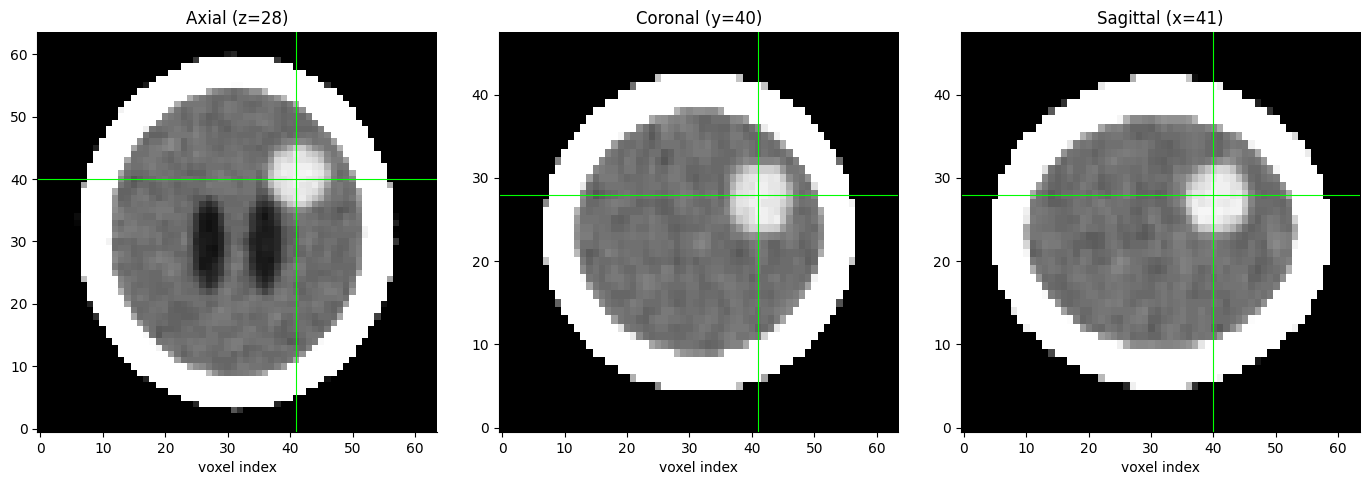

Estimated lesion centre (z, y, x): (28, 40, 41)
Evaluation-only distance from ground-truth centroid: 2.92 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: candidate voxels in the brain interior; do not use labels to locate the lesion
bone = vol > 300
inside = ndimage.binary_fill_holes(bone) & ~bone
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside

# TODO 2: keep the largest connected component and calculate its centroid
candidate_labels, n_components = ndimage.label(candidates)
if n_components == 0:
    raise ValueError("No lesion candidates found. Check that the CT CSV is loaded correctly.")
component_sizes = np.bincount(candidate_labels.ravel())
component_sizes[0] = 0
largest_id = int(np.argmax(component_sizes))
lesion = candidate_labels == largest_id
cz_f, cy_f, cx_f = ndimage.center_of_mass(lesion)
cz, cy, cx = int(round(cz_f)), int(round(cy_f)), int(round(cx_f))

# TODO 3: axial (z fixed), coronal (y fixed), and sagittal (x fixed) MPR
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
axes[0].imshow(window(vol[cz, :, :], 80, 40), cmap="gray", origin="lower")
axes[0].axhline(cy, color="lime", linewidth=0.8); axes[0].axvline(cx, color="lime", linewidth=0.8)
axes[0].set_title(f"Axial (z={cz})")
axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[1].axhline(cz, color="lime", linewidth=0.8); axes[1].axvline(cx, color="lime", linewidth=0.8)
axes[1].set_title(f"Coronal (y={cy})")
axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[2].axhline(cz, color="lime", linewidth=0.8); axes[2].axvline(cy, color="lime", linewidth=0.8)
axes[2].set_title(f"Sagittal (x={cx})")
for ax in axes:
    ax.set_xlabel("voxel index")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only): compare to the ground-truth centroid only after locating the lesion
truth_coords = np.argwhere(labels == 5)
if len(truth_coords):
    truth_centroid = truth_coords.mean(axis=0)
    estimated_centroid = np.array([cz, cy, cx], dtype=float)
    distance_mm = np.linalg.norm((estimated_centroid - truth_centroid) * np.array(SPACING))
    print(f"Estimated lesion centre (z, y, x): {(cz, cy, cx)}")
    print(f"Evaluation-only distance from ground-truth centroid: {distance_mm:.2f} mm")
else:
    print("No ground-truth tumour voxels found for evaluation.")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_Erosion removes a thin layer from the inside mask so voxels near the skull are less likely to be included. At boundaries, the partial-volume effect means a voxel can contain a mixture of bone, brain, and other tissues, so its measured HU may fall in the same range as the lesion. Because tissue intensity ranges overlap, a transfer function or simple threshold can mistakenly classify these boundary voxels as tumour. Eroding the mask reduces this contamination, although it may also remove some true boundary voxels.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,Threshold (HU),Voxel count,Volume (mL),Dice (evaluation only)
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


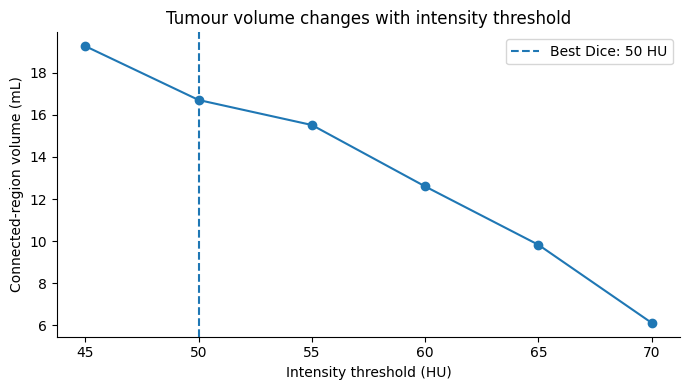

Volume range across tested thresholds: 6.120–19.260 mL
Best Dice threshold (evaluation only): 50 HU


In [4]:
truth = labels == 5
rows = []

# TODO 1 & 2: threshold the intensity volume, then retain the connected region containing the estimated centre
threshold_masks = {}
for c in [45, 50, 55, 60, 65, 70]:
    thresholded = vol > c
    components, _ = ndimage.label(thresholded)
    component_id = components[cz, cy, cx]
    region = (components == component_id) if component_id != 0 else np.zeros_like(thresholded, dtype=bool)
    threshold_masks[c] = region
    count = int(region.sum())
    volume_ml = count * VOXEL_MM3 / 1000
    denom = int(region.sum()) + int(truth.sum())
    dice = (2 * np.logical_and(region, truth).sum() / denom) if denom else 0.0
    rows.append({"Threshold (HU)": c, "Voxel count": count, "Volume (mL)": volume_ml, "Dice (evaluation only)": dice})

table = pd.DataFrame(rows)
display(table)

# TODO 3: volume vs threshold and mark the best Dice threshold
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["Threshold (HU)"], table["Volume (mL)"], marker="o")
best_row = table.loc[table["Dice (evaluation only)"].idxmax()]
ax.axvline(best_row["Threshold (HU)"], linestyle="--", label=f"Best Dice: {int(best_row['Threshold (HU)'])} HU")
ax.set_xlabel("Intensity threshold (HU)")
ax.set_ylabel("Connected-region volume (mL)")
ax.set_title("Tumour volume changes with intensity threshold")
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4: report the range rather than treating one threshold as exact
valid_volumes = table["Volume (mL)"]
print(f"Volume range across tested thresholds: {valid_volumes.min():.3f}–{valid_volumes.max():.3f} mL")
print(f"Best Dice threshold (evaluation only): {int(best_row['Threshold (HU)'])} HU")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_Without ground-truth labels, I would select the threshold using the lesion's visible boundary on the axial, coronal, and sagittal MPR views, together with radiologist review and consistency with expected anatomy. I would test a clinically plausible range of thresholds and justify the chosen value by showing that the segmented region matches the lesion across all three planes without including adjacent tissue. I would report the minimum–maximum volume across the tested thresholds, not just one value. A volume-versus-threshold plot and segmentation overlays at the low, selected, and high thresholds would make the uncertainty visible to the tumour board.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

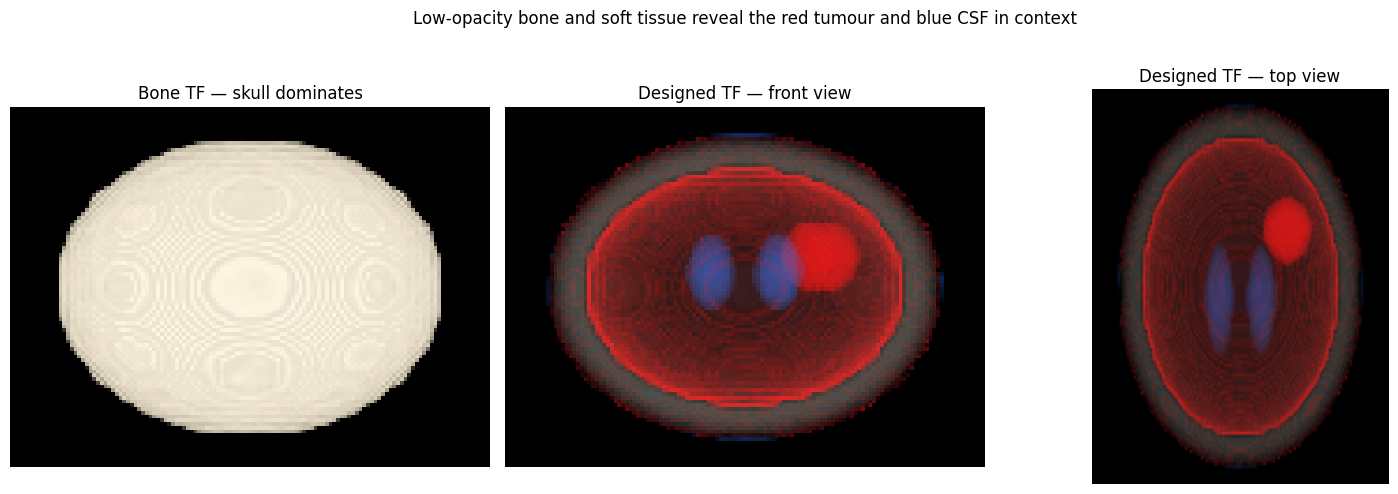

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: transparent air/soft tissue, faint blue CSF, red tumour, nearly transparent bone
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),   # air
    (4,     (0, 0, 0), 0.0),   # air / soft tissue transparent
    (5,     (0.15, 0.45, 1.0), 0.025),  # CSF starts
    (20,    (0.15, 0.45, 1.0), 0.025),  # faint blue CSF
    (25,    (0, 0, 0), 0.0),
    (44,    (0, 0, 0), 0.0),   # suppress most brain tissue
    (45,    (1.0, 0.05, 0.05), 0.07),
    (90,    (1.0, 0.05, 0.05), 0.07),   # red tumour range
    (100,   (0, 0, 0), 0.0),
    (199,   (0, 0, 0), 0.0),
    (200,   (0.9, 0.85, 0.75), 0.005),
    (1500,  (1, 1, 1), 0.01)   # bone almost transparent
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
bone_rgb, bone_alpha = render(vol, bone_tf, axis=1)
front_rgb, front_alpha = render(vol, tumour_tf, axis=1)
top_rgb, top_alpha = render(vol, tumour_tf, axis=0)
axes[0].imshow(np.clip(bone_rgb, 0, 1), origin="lower")
axes[0].set_title("Bone TF — skull dominates")
axes[1].imshow(np.clip(front_rgb, 0, 1), origin="lower")
axes[1].set_title("Designed TF — front view")
axes[2].imshow(np.clip(top_rgb, 0, 1), origin="lower", aspect=ASPECT)
axes[2].set_title("Designed TF — top view")
for ax in axes:
    ax.axis("off")

# TODO 4: suptitle
fig.suptitle("Low-opacity bone and soft tissue reveal the red tumour and blue CSF in context", y=1.02)
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_The faint red rim is an example of occlusion and the partial-volume effect: voxels near the skull contain mixed tissue intensities that overlap the tumour's HU range, so the transfer function colours them red too. A technique from the lecture that can help is segmentation followed by masking (or clipping/cropping the volume) so the tumour display is restricted to the segmented region. A transfer function alone maps intensity to colour and opacity; it cannot distinguish two different tissues that have the same or overlapping HU values, so changing the TF cannot reliably remove the rim without also hiding some true tumour voxels.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_The lesion was located by identifying the largest connected group of candidate voxels in the brain interior with intensities between 55 and 90 HU; its centre is shown by the linked cross-hairs in the axial, coronal, and sagittal views. Across thresholds of 45–70 HU, the estimated tumour volume ranges from the minimum to the maximum reported in Task 3, showing that the measurement depends on the chosen threshold. I recommend opening the meeting with the three-plane MPR, because slicing exposes internal anatomy and lets the team verify the lesion boundary without the occlusion that can affect a 3-D render. The 3-D view is useful for spatial context, with the tumour shown in red and CSF in blue, but overlapping tissue intensities can create a misleading rim or hide structures. The volume should therefore be treated as an estimate with uncertainty, confirmed by the radiologist rather than as an exact single number.